# Verify *coro_sleec*  

In [1]:
%matplotlib inline
import pickle as pkl
import numpy as np
import matplotlib.pyplot as plt
import hcipy.hcipy as hci
import coro_sleec as cor

In [2]:
pupil_dia_pxl = 481

## Verify DM Wavefront

In [3]:
# Make pupil
pupil_grid = hci.make_pupil_grid(pupil_dia_pxl)
pupil_transm = hci.circular_aperture(1)(pupil_grid)
pupil = cor.TransmMask(pupil_grid, pupil_transm)

In [4]:
print("pupil.__dict__\n{}\n".format(pupil.__dict__))
print("pupil.mask_transm.shape = {}".format(pupil.mask_transm.shape))

pupil.__dict__
{'wavelength': 1, 'input_grid': <hcipy.hcipy.field.cartesian_grid.CartesianGrid object at 0x7fe4479495f8>, 'mask_transm': Field([0., 0., 0., ..., 0., 0., 0.])}

pupil.mask_transm.shape = (231361,)


/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


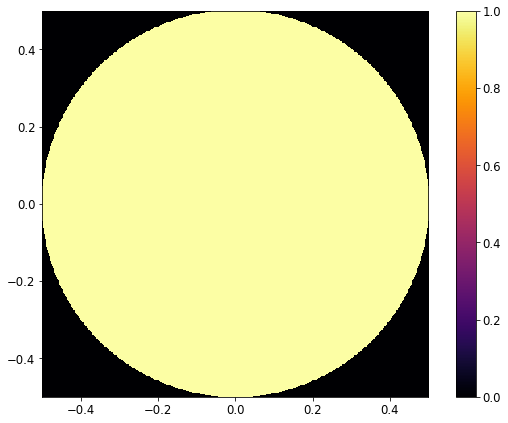

In [5]:
hci.imshow_field(pupil.mask_transm, cmap='inferno')
plt.colorbar()
plt.show()

In [6]:
inflnc_ftn = cor.InflncFtn()
try:
    inflnc_ftn.modes = inflnc_ftn.load_modes()
except FileNotFoundError:
    print("Influence-functions pickle file not found.")
    print("Generate influence functions on the fly.")
    inflnc_ftn.modes = inflnc_ftn.genrt_modes()

In [7]:
# Influenc Functions
def modlt_dm(ampl, freq, phase):
    sinsdl_actuatn = (ampl)*np.cos(
                                    2.0*np.pi*(freq)*np.indices((48,48))[1] + phase
                                            ).ravel()
    return cor.DefrmblMirror(inflnc_ftn.make_surfc(sinsdl_actuatn))

/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


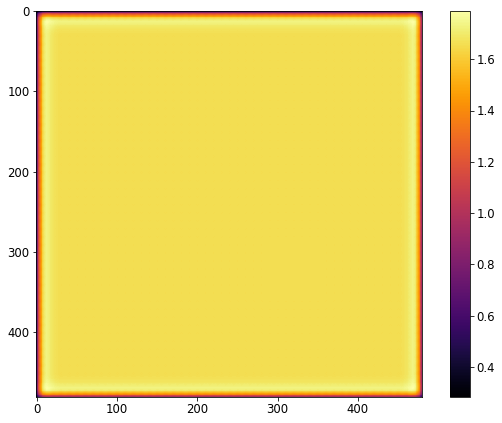

In [8]:
# Plot uniform actuation to illustrate free-stroke to single-actuator ratios
actuatn_ones = np.ones((48,48)).ravel()
norm_surfc = inflnc_ftn.make_surfc(actuatn_ones)
wid = int(np.sqrt(norm_surfc.size))
norm_surfc = norm_surfc.reshape(wid,wid)
plt.imshow(norm_surfc, cmap="inferno")
plt.colorbar()
plt.show()

In [9]:
print("max. free stroke = {}".format(norm_surfc.max()))
print("center free stroke = {}".format(norm_surfc[wid//2, wid//2]))

max. free stroke = 1.7888068045080716
center free stroke = 1.6598835330891455


In [10]:
# Make DM1
mod_ampl = 0.001
mod_freq = 0.0/48
mod_phase = 0.0
dm1 = modlt_dm(mod_ampl, mod_freq, mod_phase)
dm1_out = dm1(hci.Wavefront(pupil.mask_transm))
print("dm1_out.amplitude.max() = {}".format(dm1_out.amplitude.max()))
print("dm1_out.amplitude.min() = {}".format(dm1_out.amplitude.min()))
print("dm1_out.phase.max() = {}".format(dm1_out.phase.max()))
print("dm1_out.phase.min() = {}".format(dm1_out.phase.min()))
print("max. free stroke = {}".format(dm1_out.phase.max()/(2*mod_ampl*2*np.pi)))
print("center free stroke = {}".format(dm1_out.phase.reshape(wid, wid)[wid//2, wid//2]/(2*mod_ampl*2*np.pi)))

dm1_out.amplitude.max() = 1.0
dm1_out.amplitude.min() = 0.0
dm1_out.phase.max() = 0.02177284125537642
dm1_out.phase.min() = 0.0
max. free stroke = 1.7326276554741524
center free stroke = 1.6598835330891466


/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


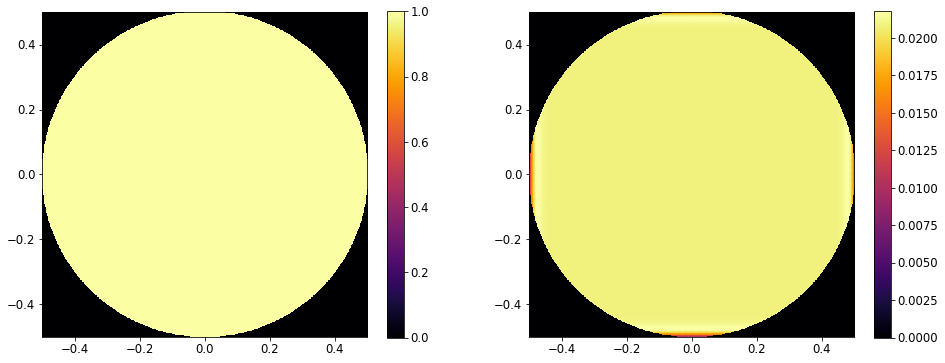

In [11]:
plt.figure(figsize=(16, 6))
plt.subplot(121)
hci.imshow_field(dm1_out.amplitude, cmap='inferno')
plt.colorbar()
plt.subplot(122)
hci.imshow_field(dm1_out.phase, cmap='inferno')
plt.colorbar()
plt.show()

## Verify Propagation  

In [12]:
ampl = 0.1
freq = 12.0
phase = 0.0
dm1_array = (ampl)*np.cos(
                       2.0*np.pi*(freq)*np.indices((48,48))[1] + phase
                         ).ravel()
corongrph, psf, camera_wf, normlzd_intnsty, comptng_time = (
    cor._test(dm1_array=dm1_array)
                                                        )
print(comptng_time)

4.01607871055603


/home/pinchen/anaconda2/envs/py3/lib/python3.5/site-packages/matplotlib/font_manager.py:1328: UserWarning: findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans
  (prop.get_family(), self.defaultFamily[fontext]))


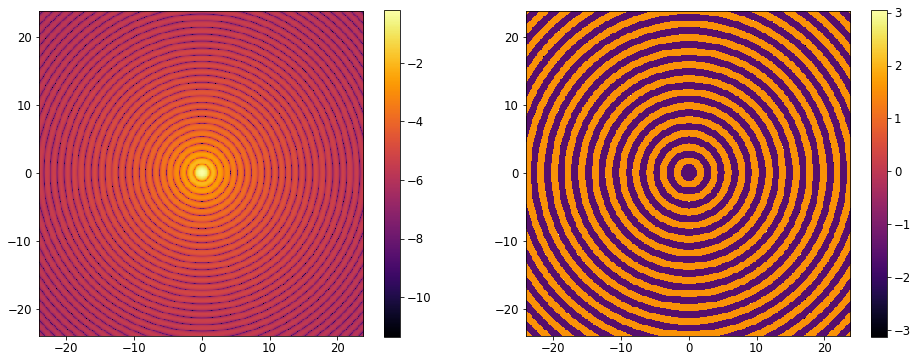

In [13]:
plt.figure(figsize=(16, 6))
plt.subplot(121)
hci.imshow_field(np.log10(psf.intensity), cmap='inferno')
plt.colorbar()
plt.subplot(122)
hci.imshow_field(psf.phase, cmap='inferno')
plt.colorbar()
plt.show()